In [1]:
##################
### Keagan Moo ###
### 2025/06/28 ###
### ATAC Age   ###
##################

# This script loads in the glmnb output, tabulates and graphs those results for a given cell type

suppressPackageStartupMessages({library(SingleCellExperiment)
library(Seurat)
library(Matrix)
library(dplyr)
library(ggplot2)
library(glue)
library(lmtest)
library(DESeq2)
library(ggupset)
library(ggpattern)
library(purrr)})

In [ ]:
# This section begins a sanity check segment and is not part of the core workflow. Here we load in the total peak by nuclei count data and seperate by sex
cDex <- "Type_1"
small <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/{cDex}_FUSIONsnATAC_sce.rds"))
smallF <- small[,small$sex == "F"]
smallM <- small[,small$sex == "M"]
meta <- droplevels(colData(small))
length(unique(colData(small)$sample))
dim(small)

In [15]:
# Filter out peaks that do not have at least 1 count in 10% of nuclei
keepRows <- rowSums(counts(small) >= 1) >= ncol(counts(small))*0.1
small <- small[keepRows,]
keepRowsF <- rowSums(counts(smallF) >= 1) >= ncol(counts(smallF))*0.1
smallF <- smallF[keepRowsF,]
keepRowsM <- rowSums(counts(smallM) >= 1) >= ncol(counts(smallM))*0.1
smallM <- smallM[keepRowsM,]

In [16]:
# Get an idea of the samples going in to each analysis as not all samples have nuclei of each type left over after filtering
length(unique(colData(smallM)$sample))
length(unique(colData(smallF)$sample))

dim(meta[meta$sample == "12095--499",])
inSamples <- data.frame(colData(small)) %>% select(batch, sample, sex, age, bmi, ogtt) %>% unique()
rownames(inSamples) <- NULL
inSamplesF <- data.frame(colData(smallM)) %>% select(batch, sample, sex, age, bmi, ogtt) %>% unique()
rownames(inSamplesF) <- NULL
inSamplesM <- data.frame(colData(smallF)) %>% select(batch, sample, sex, age, bmi, ogtt) %>% unique()
rownames(inSamplesM) <- NULL
dim(inSamplesM)
dim(inSamplesF)

#inSamplesM$sample
write.csv(inSamples, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/Table3S/{cDex}_ATAC_JointSamples.csv"))
write.csv(inSamplesF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/Table3S/{cDex}_ATAC_FemaleSamples.csv"))
write.csv(inSamplesM, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/Table3S/{cDex}_ATAC_MaleSamples.csv"))

[1] 164

[1] 120

[1] 208  21

[1] 120   6

[1] 164   6

In [10]:
# Test for quality of these nuclei by checking association for metadata values
cor.test(colData(smallF)$age, colData(smallF)$fraction_mitochondrial, method = "spearman")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/mitoFVAge_{cDex}_F.pdf"), width=6, height=6)
    mygg <- ggplot(data=colData(smallF), aes(x=age, y=tss_enrichment)) +
        geom_point(alpha = 0.05, position = position_jitter(width = 0.01)) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("mitochondrial_fraction") 
   print(mygg)
dev.off()
cor.test(colData(smallM)$age, colData(smallM)$fraction_mitochondrial, method = "spearman")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/mitoFVAge_{cDex}_M.pdf"), width=6, height=6)
    mygg <- ggplot(data=colData(smallM), aes(x=age, y=tss_enrichment)) +
        geom_point(alpha = 0.05, position = position_jitter(width = 0.01)) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("mitochondrial_fraction") 
   print(mygg)
dev.off()

Warning message in cor.test.default(colData(smallF)$age, colData(smallF)$fraction_mitochondrial, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  colData(smallF)$age and colData(smallF)$fraction_mitochondrial
S = 8.5085e+12, p-value = 0.4433
alternative hypothesis: true rho is not equal to 0
sample estimates:
        rho 
0.003977593 


pdf 
  2

Warning message in cor.test.default(colData(smallM)$age, colData(smallM)$fraction_mitochondrial, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  colData(smallM)$age and colData(smallM)$fraction_mitochondrial
S = 9.7947e+12, p-value = 8.207e-12
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
0.03445253 


pdf 
  2

In [3]:
meta <- droplevels(colData(small))
meta$batch = as.factor(meta$batch)
meta$ogtt = as.factor(meta$ogtt)
meta$bmi = as.numeric(meta$bmi)
meta$age = as.numeric(meta$age)
metaF <- meta[meta$sex == "F",]
metaM <- meta[meta$sex == "M",]
rm(small)

In [4]:
metaF$pre_counts <- as.numeric(colSums(counts(smallF))+1)
metaM$pre_counts <- as.numeric(colSums(counts(smallM))+1)

In [5]:
keepRowsF <- rowSums(counts(smallF) >= 1) >= ncol(counts(smallF))*0.1
smallF <- smallF[keepRowsF,]
keepRowsM <- rowSums(counts(smallM) >= 1) >= ncol(counts(smallM))*0.1
smallM <- smallM[keepRowsM,]

In [6]:
metaF$post_counts <- as.numeric(colSums(counts(smallF))+1)
metaM$post_counts <- as.numeric(colSums(counts(smallM))+1)
#metaF
#metaM

DataFrame with 14524 rows and 23 columns
                                                index     SNG.1ST    UMAP_1
                                          <character> <character> <numeric>
atac.499.NM.1.AAACTCGAGTATACGA atac.499.NM.1.AAACTC..       32048  -3.53715
atac.499.NM.1.AAATGAGCAATGACTC atac.499.NM.1.AAATGA..       32052  -3.00428
atac.499.NM.1.AAATGCCAGCCTCGCA atac.499.NM.1.AAATGC..       32052  -5.56789
atac.499.NM.1.AACATCGCATCAGAAA atac.499.NM.1.AACATC..       32054  -1.53000
atac.499.NM.1.AACCGATCAATCCATG atac.499.NM.1.AACCGA..       32074  -6.51312
...                                               ...         ...       ...
atac.692.NM.8.TTTACGTAGGAAGGTA atac.692.NM.8.TTTACG..       32069  -5.64033
atac.692.NM.8.TTTGAGGAGTGGGACT atac.692.NM.8.TTTGAG..       22041  -2.72442
atac.692.NM.8.TTTGCGCAGTGAATAC atac.692.NM.8.TTTGCG..       32109  -2.28875
atac.692.NM.8.TTTGCGCTCGCGTTCT atac.692.NM.8.TTTGCG..       32109  -1.79441
atac.692.NM.8.TTTGGCCCATATTGGC atac.692.NM.8.TT

DataFrame with 28280 rows and 23 columns
                                                index     SNG.1ST    UMAP_1
                                          <character> <character> <numeric>
atac.499.NM.1.AAACTGCCACAGGTAG atac.499.NM.1.AAACTG..       12094  -5.70362
atac.499.NM.1.AAAGGATGTATGCTAC atac.499.NM.1.AAAGGA..       32001  -4.91979
atac.499.NM.1.AAAGGGCAGTTCCAGT atac.499.NM.1.AAAGGG..       12011  -2.00075
atac.499.NM.1.AAAGGGCGTTAGGAGC atac.499.NM.1.AAAGGG..       12136  -4.98213
atac.499.NM.1.AAATGAGTCGAGGTCC atac.499.NM.1.AAATGA..       22008  -6.90935
...                                               ...         ...       ...
atac.692.NM.8.TTGGTCCGTTGAAGCG atac.692.NM.8.TTGGTC..       22039 -6.105246
atac.692.NM.8.TTGTCTAAGACCCATT atac.692.NM.8.TTGTCT..       32018  0.374439
atac.692.NM.8.TTGTCTAAGTGATAAC atac.692.NM.8.TTGTCT..       22039 -6.347544
atac.692.NM.8.TTGTCTAGTACCTATG atac.692.NM.8.TTGTCT..       12073 -5.726154
atac.692.NM.8.TTTGGTTGTAGCCATT atac.692.NM.8.TT

In [7]:
metaF$lossP <- (1 - (metaF$post_counts / metaF$pre_counts))
metaM$lossP <- (1 - (metaM$post_counts / metaM$pre_counts))

In [8]:
# Test to see if the loss of counts from nuclei is potentially an age-associated confounder
cor.test(metaF$age, metaF$post_counts, method = "spearman")
cor.test(metaM$age, metaM$post_counts, method = "spearman")

Warning message in cor.test.default(metaF$age, metaF$post_counts, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  metaF$age and metaF$post_counts
S = 5.3253e+11, p-value = 2.347e-07
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
-0.042879 


Warning message in cor.test.default(metaM$age, metaM$post_counts, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  metaM$age and metaM$post_counts
S = 3.8041e+12, p-value = 0.1225
alternative hypothesis: true rho is not equal to 0
sample estimates:
         rho 
-0.009184123 


In [9]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/postCountsVAge_Type2x_F.pdf"), width=6, height=6)
    mygg <- ggplot(data=metaF, aes(x=age, y=post_counts)) +
        geom_point(alpha = 0.1, position = position_jitter(width = 0.01)) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("Total Counts Per Nuclei") 
   print(mygg)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/postCountsVAge_Type2x_M.pdf"), width=6, height=6)
    mygg <- ggplot(data=metaM, aes(x=age, y=post_counts)) +
        geom_point(alpha = 0.1, position = position_jitter(width = 0.01)) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("Total Counts Per Nuclei") 
   print(mygg)
dev.off()

pdf 
  2

pdf 
  2

In [9]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FilterCountsLossPreVPost_Type2a_F_Nuc.pdf"), width=6, height=6)
    mygg <- ggplot(data=metaF, aes(x=pre_counts, y=post_counts)) +
        geom_point(alpha = 0.02) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        xlab("Pre Filter Total Counts") + ylab("Post Filter Total Counts") 
   print(mygg)
dev.off()
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FilterCountsLossPreVPost_Type2a_M_Nuc.pdf"), width=6, height=6)
    mygg <- ggplot(data=metaM, aes(x=pre_counts, y=post_counts)) +
        geom_point(alpha = 0.02) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        xlab("Pre Filter Total Counts") + ylab("Post Filter Total Counts") 
   print(mygg)
dev.off()

pdf 
  2

pdf 
  2

In [ ]:
metadataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/cluster_info_qc.tsv", sep = "\t", header = TRUE)
batchdataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/batch-sample-info-full.tsv", sep = "\t", header = TRUE)
metadataFactors <- metadataFactors[(metadataFactors$modality == "atac") & (metadataFactors$demux_cat != "multiome"),]
metadataFactors <- merge(metadataFactors, batchdataFactors, by = "SNG.1ST")

In [2]:
# This section begins the main workflow loading in the GLMMNB results for a given cell type

cDex <- "Type_1"
libDir <- "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/"
libListF <- list.files(libDir, pattern = glue("^F_pTSS_{cDex}\\.*"))
libListM <- list.files(libDir, pattern = glue("^M_pTSS_{cDex}\\.*"))
libList <- list.files(libDir, pattern = glue("^pTSS_{cDex}\\.*"))
#libList

In [7]:
head(read.table(file = paste0(libDir, libListF[1]), sep = "\t"))

,index,group_i,estimate,se,z,p_GLMMNB,p_LRT
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr1:1000015:1000316,age,0.0011402695,0.004004876,0.2847203,0.7758584,0.7759151
2,chr1:100037924:100038225,age,-0.0006158822,0.001512483,-0.4071995,0.6838615,0.6840233
3,chr1:100132863:100133164,age,-0.0011314511,0.001162722,-0.9731051,0.3305011,0.3310684
4,chr1:100178145:100178446,age,-0.0032632698,0.003429440,-0.9515459,0.3413273,0.3421752
5,chr1:1001840:1002141,age,-0.0006172708,0.002090231,-0.2953122,0.7677554,0.7673589
6,chr1:100187982:100188283,age,0.0040025249,0.003781126,1.0585538,0.2898030,0.2898834


In [3]:
# Combine the different results files from GLMMNB into one file for analysis
seedFrame <- read.table(file = paste0(libDir, libList[1]), sep = "\t")
seedFrameF <- read.table(file = paste0(libDir, libListF[1]), sep = "\t")
seedFrameM <- read.table(file = paste0(libDir, libListM[1]), sep = "\t")
libList <- libList[-1]
libListF <- libListF[-1]
libListM <- libListM[-1]

for (file in libListF) {
    #print(paste0(libDir, file))
    file <- substring(file,3,nchar(file))
    tempFrameF <- read.table(file = paste0(libDir,"F_" , file), sep = "\t")
    tempFrameM <- read.table(file = paste0(libDir,"M_", file), sep = "\t")
    seedFrameF <- rbind(seedFrameF, tempFrameF)
    seedFrameM <- rbind(seedFrameM, tempFrameM)
}
for (file in libList) {
    tempFrame <- read.table(file = paste0(libDir, file), sep = "\t")
    seedFrame <- rbind(seedFrame, tempFrame)    
}
# it turns out we get an overlap of 1 peak per chunk (+1) when running the GLMNB nextflow job. not an expensive or really concerning issue, but might need to go back and fix
# currently the addition of "distinct" solves this
seedFrame <- seedFrame %>% arrange(p_LRT) %>% distinct()
seedFrame$p_FDR <- p.adjust(seedFrame$p_LRT, method = "fdr")
seedFrameF <- seedFrameF %>% arrange(p_LRT) %>% distinct()
seedFrameF$p_FDR <- p.adjust(seedFrameF$p_LRT, method = "fdr")
seedFrameM <- seedFrameM %>% arrange(p_LRT) %>% distinct()
seedFrameM$p_FDR <- p.adjust(seedFrameM$p_LRT, method = "fdr")

seedFrame <- seedFrame[complete.cases(seedFrame), ]
seedFrameF <- seedFrameF[complete.cases(seedFrameF), ]
seedFrameM <- seedFrameM[complete.cases(seedFrameM), ]

rownames(seedFrame) <- seedFrame$index
rownames(seedFrameF) <- seedFrameF$index
rownames(seedFrameM) <- seedFrameM$index

In [4]:
write.table(seedFrame, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/pTSS_Agg_{cDex}.tsv"), sep = "\t")
write.table(seedFrameF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_{cDex}.tsv"), sep = "\t")
write.table(seedFrameM, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_{cDex}.tsv"), sep = "\t")
#seedFrameFTSS <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/F_pTSS_Agg_{cDex}.tsv"), sep = "\t")
#seedFrameMTSS <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/M_pTSS_Agg_{cDex}.tsv"), sep = "\t")

In [4]:
write.table(seedFrame, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/pTSS_Agg_{cDex}.csv"), sep = ",")
write.table(seedFrameF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_{cDex}.csv"), sep = ",")
write.table(seedFrameM, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_{cDex}.csv"), sep = ",")

In [5]:
# Report significant hit numbers from the aggregated files

print(dim(seedFrameF))
#print(head(seedFrameF))
#plot(x = seedFrame$p_GLMMNB, y = seedFrame$p_LRT)
print("Combined")
nrow(seedFrame[seedFrame$p_FDR < 0.1,])
nrow(seedFrame[seedFrame$p_FDR < 0.05,])
nrow(seedFrame[seedFrame$p_LRT < 0.05,])
#hist(seedFrame$p_LRT)
print("Female")
nrow(seedFrameF[seedFrameF$p_FDR < 0.1,])
nrow(seedFrameF[seedFrameF$p_FDR < 0.05,])
#hist(seedFrameF$estimate)
nrow(seedFrameF[seedFrameF$p_LRT < 0.05,])
#hist(seedFrameF$p_LRT)
print("Male")
nrow(seedFrameM[seedFrameM$p_FDR < 0.1,])
nrow(seedFrameM[seedFrameM$p_FDR < 0.05,])
#hist(seedFrameM$estimate)
nrow(seedFrameM[seedFrameM$p_LRT < 0.05,])
#hist(seedFrameM$p_LRT)

[1] 40827     8
[1] "Combined"


[1] 2

[1] 2

[1] 2294

[1] "Female"


...

[1] 2487

[1] "Male"


[1] 2

[1] 0

[1] 2232

In [4]:
# Load in the pseudobulk DESeq2 results for comparison to the GLMMNB results

DESeq2Res <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Res/AgeATAC/{cDex}_DESeq2.rds"))[[1]]
DESeq2Res <- data.frame(DESeq2Res) %>% arrange(pvalue)
DESeq2ResF <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Res/AgeATAC/{cDex}_DESeq2.rds"))[[2]]
DESeq2ResF <- data.frame(DESeq2ResF) %>% arrange(pvalue)
DESeq2ResM <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Res/AgeATAC/{cDex}_DESeq2.rds"))[[3]]
DESeq2ResM <- data.frame(DESeq2ResM) %>% arrange(pvalue)
dim(DESeq2ResF)

[1] 79136     5

In [7]:
print("Combined")
nrow(DESeq2Res[DESeq2Res$padj < 0.1,])
nrow(DESeq2Res[(DESeq2Res$padj < 0.1) & (DESeq2Res$log2FoldChange < 0),])
nrow(DESeq2Res[(DESeq2Res$padj < 0.1) & (DESeq2Res$log2FoldChange > 0),])
print("Female")
nrow(DESeq2ResF[DESeq2ResF$padj < 0.1,])
nrow(DESeq2ResF[(DESeq2ResF$padj < 0.1) & (DESeq2ResF$log2FoldChange < 0),])
nrow(DESeq2ResF[(DESeq2ResF$padj < 0.1) & (DESeq2ResF$log2FoldChange > 0),])
print("Male")
nrow(DESeq2ResM[DESeq2ResM$padj < 0.1,])
nrow(DESeq2ResM[(DESeq2ResM$padj < 0.1) & (DESeq2ResM$log2FoldChange < 0),])
nrow(DESeq2ResM[(DESeq2ResM$padj < 0.1) & (DESeq2ResM$log2FoldChange > 0),])

[1] "Combined"


[1] 2429

[1] 1221

[1] 1208

[1] "Female"


...

[1] 9

[1] "Male"


[1] 772

[1] 464

[1] 308

In [10]:
# -log10(p-value) * coefficient plots comparing the pseudobulk DESeq2 data to the single-nuclei GLMMNB results

batchCompDatF <- merge(seedFrameF, data.frame(DESeq2ResF), by= "row.names") %>% dplyr::select(index, p_LRT, estimate, p_FDR, pvalue, log2FoldChange, padj)
batchCompDatF$modp.x <- -log10(batchCompDatF$p_LRT)*sign(batchCompDatF$estimate)
batchCompDatF$modp.y <- -log10(batchCompDatF$pvalue)*sign(batchCompDatF$log2FoldChange)
#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$p_FDR)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$p_FDR)),]$p_FDR <- 1
}
if (nrow(batchCompDatF[(is.na(batchCompDatF$padj)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$padj)),]$padj <- 1
}

#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$p_FDR < 0.05,]$ColorBlock <- "FDR < 0.05 in GLMMNB"
batchCompDatF[batchCompDatF$padj < 0.05,]$ColorBlock <- "FDR < 0.05 in DESeq2"
batchCompDatF[(batchCompDatF$padj < 0.05) & (batchCompDatF$p_FDR < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(pvalue)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
ourLine <- lm(batchCompDatF$modp.y~batchCompDatF$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMMNBvDESeq2_pvalCompare_{cDex}_Fe_FRD005.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(p_LRT)*sign(estimate), y=-log10(pvalue)*sign(log2FoldChange))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-11,11) + ylim(-11,11) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(slope=1, intercept=0, linetype = "dashed") +
        scale_color_manual(values=c("#000000", "#DD44DD")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

batchCompDatM <- merge(seedFrameM, data.frame(DESeq2ResM), by= "row.names") %>% dplyr::select(index, p_LRT, estimate, p_FDR, pvalue, log2FoldChange, padj)
batchCompDatM$modp.x <- -log10(batchCompDatM$p_LRT)*sign(batchCompDatM$estimate)
batchCompDatM$modp.y <- -log10(batchCompDatM$pvalue)*sign(batchCompDatM$log2FoldChange)
#head(batchCompDatM)
if (nrow(batchCompDatM[(is.na(batchCompDatM$p_FDR)),]) > 0) {
    batchCompDatM[(is.na(batchCompDatM$p_FDR)),]$p_FDR <- 1
}
if (nrow(batchCompDatM[(is.na(batchCompDatM$padj)),]) > 0) {
    batchCompDatM[(is.na(batchCompDatM$padj)),]$padj <- 1
}

#head(batchCompDatM)
batchCompDatM$ColorBlock <- rep("Niether", nrow(batchCompDatM))
batchCompDatM[batchCompDatM$p_FDR < 0.05,]$ColorBlock <- "FDR < 0.05 in GLMMNB"
batchCompDatM[batchCompDatM$padj < 0.05,]$ColorBlock <- "FDR < 0.05 in DESeq2"
batchCompDatM[(batchCompDatM$padj < 0.05) & (batchCompDatM$p_FDR < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
batchCompDatMPrint <- batchCompDatM %>% arrange(pvalue)
batchCompDatM <- batchCompDatM[batchCompDatM$ColorBlock != "Niether",]
ourLine <- lm(batchCompDatM$modp.y~batchCompDatM$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMMNBvDESeq2_pvalCompare_{cDex}_Ma_FRD005.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDatM, aes(x=-log10(p_LRT)*sign(estimate), y=-log10(pvalue)*sign(log2FoldChange))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-11,11) + ylim(-11,11) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(slope=1, intercept=0, linetype = "dashed") +
        scale_color_manual(values=c("#000000", "#229922", "#DD44DD")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMMNBvDESeq2_pvalCompare_LEDGE_FRD005.pdf"), width=4.5, height=3)
    mygg <- ggplot(data=batchCompDatM, aes(x=-log10(p_LRT)*sign(estimate), y=-log10(pvalue)*sign(log2FoldChange))) +
        geom_point(aes(color = ColorBlock), alpha = 0.9, size = 4)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24)) + xlim(-11,11) + ylim(-11,11) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(slope=1, intercept=0, linetype = "dashed") +
        scale_color_manual(values=c("#000000", "#229922", "#DD44DD")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()


[1] 0.9110813

pdf 
  2

[1] 0.9087851

pdf 
  2

pdf 
  2

In [6]:
# Calculating the percentage of peaks in each quadrant of the plots for indication in the manuscript figures

nrow(batchCompDatF[(batchCompDatF$estimate > 0) & (batchCompDatF$log2FoldChange > 0),])
nrow(batchCompDatF[(batchCompDatF$estimate > 0) & (batchCompDatF$log2FoldChange > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$estimate < 0) & (batchCompDatF$log2FoldChange < 0),])
nrow(batchCompDatF[(batchCompDatF$estimate < 0) & (batchCompDatF$log2FoldChange < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$estimate > 0) & (batchCompDatF$log2FoldChange < 0),])
nrow(batchCompDatF[(batchCompDatF$estimate > 0) & (batchCompDatF$log2FoldChange < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$estimate < 0) & (batchCompDatF$log2FoldChange > 0),])
nrow(batchCompDatF[(batchCompDatF$estimate < 0) & (batchCompDatF$log2FoldChange > 0),])/nrow(batchCompDatF)

nrow(batchCompDatM[(batchCompDatM$estimate > 0) & (batchCompDatM$log2FoldChange > 0),])
nrow(batchCompDatM[(batchCompDatM$estimate > 0) & (batchCompDatM$log2FoldChange > 0),])/nrow(batchCompDatM)
nrow(batchCompDatM[(batchCompDatM$estimate < 0) & (batchCompDatM$log2FoldChange < 0),])
nrow(batchCompDatM[(batchCompDatM$estimate < 0) & (batchCompDatM$log2FoldChange < 0),])/nrow(batchCompDatM)
nrow(batchCompDatM[(batchCompDatM$estimate > 0) & (batchCompDatM$log2FoldChange < 0),])
nrow(batchCompDatM[(batchCompDatM$estimate > 0) & (batchCompDatM$log2FoldChange < 0),])/nrow(batchCompDatM)
nrow(batchCompDatM[(batchCompDatM$estimate < 0) & (batchCompDatM$log2FoldChange > 0),])
nrow(batchCompDatM[(batchCompDatM$estimate < 0) & (batchCompDatM$log2FoldChange > 0),])/nrow(batchCompDatM)

[1] 5

[1] 0.2631579

[1] 14

[1] 0.7368421

[1] 0

...

[1] 0.6575758

[1] 0

[1] 0

[1] 0

[1] 0

In [4]:
# -log10(p-value) * coefficient plots comparing the female and male results

batchCompDat <- merge(seedFrameF, seedFrameM, by= "row.names") %>% dplyr::select(p_LRT.x, estimate.x, p_FDR.x, p_LRT.y, estimate.y, p_FDR.y)
batchCompDat$modp.x <- -log10(batchCompDat$p_LRT.x)*sign(batchCompDat$estimate.x)
batchCompDat$modp.y <- -log10(batchCompDat$p_LRT.y)*sign(batchCompDat$estimate.y)
#head(batchCompDat)
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.x)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.y)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.y)),]$p_FDR.y <- 1
}
print("One")
head(batchCompDat)
batchCompDat$ColorBlock <- rep("Niether", nrow(batchCompDat))
batchCompDat[batchCompDat$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Female"
batchCompDat[batchCompDat$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Male"
batchCompDat[(batchCompDat$p_FDR.y < 0.05) & (batchCompDat$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
batchCompDatPrint <- batchCompDat %>% arrange(p_LRT.x)
batchCompDat <- batchCompDat[batchCompDat$ColorBlock != "Niether",]
ourLine <- lm(batchCompDat$modp.y~batchCompDat$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FemalevMale_pvalCompare_{cDex}_FDR005_pTSS.pdf"), width=4.5, height=5)
    mygg <- ggplot(data=batchCompDat, aes(x=-log10(p_LRT.x)*sign(estimate.x), y=-log10(p_LRT.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.2, size = 2)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-11,11) + ylim(-11,11) + 
        scale_color_manual(values=c("#000000", "#FF2222", "#2222FF")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FemalevMale_pvalCompare_Ledge.pdf"), width=10, height=1)
    mygg <- ggplot(data=batchCompDat, aes(x=-log10(p_LRT.x)*sign(estimate.x), y=-log10(p_LRT.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.9, size = 4)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=24)) + xlim(-11,11) + ylim(-11,11) + 
        scale_color_manual(values=c("#000000", "#FF2222", "#2222FF")) + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        guides(color=guide_legend(nrow=1), shape=guide_legend(nrow=1))
   print(mygg)
dev.off()

nrow(batchCompDat[(batchCompDat$p_FDR.y < 0.05) & (batchCompDat$p_FDR.x < 0.05),])

[1] "One"


,p_LRT.x,estimate.x,p_FDR.x,p_LRT.y,estimate.y,p_FDR.y,modp.x,modp.y
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.310001439,0.0029815218,0.7080049,0.31770502,0.0033026971,0.8196662,0.508636291,0.49797592
2,0.007736628,-0.0030926198,0.1737460,0.04804573,0.0024017603,0.5284418,-2.111448311,1.31834522
3,0.813844593,-0.0002078153,0.9485310,0.52154137,-0.0006338343,0.8969802,-0.089458517,-0.28271124
4,0.648719526,-0.0012114617,0.8902024,0.42720528,-0.0017672548,0.8661473,-0.187943030,-0.36936339
5,0.991081317,0.0000182247,0.9973339,0.32341563,0.0015309380,0.8232012,0.003890711,0.49023899
6,0.026587564,0.0053298554,0.2879436,0.88331056,-0.0003367500,0.9827843,1.575321455,-0.05388658


[1] 0.1800222

pdf 
  2

pdf 
  2

[1] 1

In [6]:
nrow(batchCompDat[(batchCompDat$modp.x > 0) & (batchCompDat$modp.y > 0),])
nrow(batchCompDat[(batchCompDat$modp.x > 0) & (batchCompDat$modp.y > 0),])/nrow(batchCompDat)
nrow(batchCompDat[(batchCompDat$modp.x < 0) & (batchCompDat$modp.y < 0),])
nrow(batchCompDat[(batchCompDat$modp.x < 0) & (batchCompDat$modp.y < 0),])/nrow(batchCompDat)
nrow(batchCompDat[(batchCompDat$modp.x > 0) & (batchCompDat$modp.y < 0),])
nrow(batchCompDat[(batchCompDat$modp.x > 0) & (batchCompDat$modp.y < 0),])/nrow(batchCompDat)
nrow(batchCompDat[(batchCompDat$modp.x < 0) & (batchCompDat$modp.y > 0),])
nrow(batchCompDat[(batchCompDat$modp.x < 0) & (batchCompDat$modp.y > 0),])/nrow(batchCompDat)

[1] 101

[1] 0.3754647

[1] 119

[1] 0.4423792

[1] 23

[1] 0.08550186

[1] 26

[1] 0.09665428

In [6]:
# Comparing Two models
batchCompDat <- merge(seedFrameF, seedFrameFTSS, by= "row.names") %>% dplyr::select(p_LRT.x, estimate.x, p_FDR.x, p_LRT.y, estimate.y, p_FDR.y)
batchCompDat$modp.x <- -log10(batchCompDat$p_LRT.x)*sign(batchCompDat$estimate.x)
batchCompDat$modp.y <- -log10(batchCompDat$p_LRT.y)*sign(batchCompDat$estimate.y)
#head(batchCompDat)
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.x)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.y)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.y)),]$p_FDR.y <- 1
}
print("One")
batchCompDat$ColorBlock <- rep("Niether", nrow(batchCompDat))
batchCompDat[batchCompDat$p_FDR.x < 0.1,]$ColorBlock <- "FDR < 0.1 w/o TSS"
batchCompDat[batchCompDat$p_FDR.y < 0.1,]$ColorBlock <- "FDR < 0.1 w/ TSS"
batchCompDat[(batchCompDat$p_FDR.y < 0.1) & (batchCompDat$p_FDR.x < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
batchCompDatPrint <- batchCompDat %>% arrange(p_LRT.x)
batchCompDat <- batchCompDat[batchCompDat$ColorBlock != "Niether",]
ourLine <- lm(batchCompDat$modp.y~batchCompDat$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/wTSS_pvalCompare_{cDex}_Fe_FDR01.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDat, aes(x=-log10(p_LRT.x)*sign(estimate.x), y=-log10(p_LRT.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + xlim(-11,11) + ylim(-11,11) +
        xlab("w/o TSS -log10(Nominal P-value)*sign(log2FC)") + ylab("w/ TSS -log10(Nominal P-value)*sign(log2FC)") + ggtitle(glue("Comparing Nominal P-values")) 
   print(mygg)
dev.off()

batchCompDat <- merge(seedFrameM, seedFrameMTSS, by= "row.names") %>% dplyr::select(p_LRT.x, estimate.x, p_FDR.x, p_LRT.y, estimate.y, p_FDR.y)
batchCompDat$modp.x <- -log10(batchCompDat$p_LRT.x)*sign(batchCompDat$estimate.x)
batchCompDat$modp.y <- -log10(batchCompDat$p_LRT.y)*sign(batchCompDat$estimate.y)
#head(batchCompDat)
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.x)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(batchCompDat[(is.na(batchCompDat$p_FDR.y)),]) > 0) {
    batchCompDat[(is.na(batchCompDat$p_FDR.y)),]$p_FDR.y <- 1
}
print("One")
batchCompDat$ColorBlock <- rep("Niether", nrow(batchCompDat))
batchCompDat[batchCompDat$p_FDR.x < 0.1,]$ColorBlock <- "FDR < 0.1 w/o TSS"
batchCompDat[batchCompDat$p_FDR.y < 0.1,]$ColorBlock <- "FDR < 0.1 w/ TSS"
batchCompDat[(batchCompDat$p_FDR.y < 0.1) & (batchCompDat$p_FDR.x < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
batchCompDatPrint <- batchCompDat %>% arrange(p_LRT.x)
batchCompDat <- batchCompDat[batchCompDat$ColorBlock != "Niether",]
ourLine <- lm(batchCompDat$modp.y~batchCompDat$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/wTSS_pvalCompare_{cDex}_Ma_FDR01.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDat, aes(x=-log10(p_LRT.x)*sign(estimate.x), y=-log10(p_LRT.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + xlim(-11,11) + ylim(-11,11) +
        xlab("w/o TSS -log10(Nominal P-value)*sign(log2FC)") + ylab("w/ TSS -log10(Nominal P-value)*sign(log2FC)") + ggtitle(glue("Comparing Nominal P-values")) 
   print(mygg)
dev.off()

[1] "One"


[1] 1.00318

pdf 
  2

[1] "One"


[1] 1.002136

pdf 
  2

In [6]:
batchCompDat[batchCompDat$p_FDR.x < 0.1,]

,p_LRT.x,estimate.x,p_FDR.x,p_LRT.y,estimate.y,p_FDR.y,modp.x,modp.y,ColorBlock
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
363,1.010849e-04,0.01112874,0.07913804,0.46836780,2.327117e-03,0.9711321,3.995314,0.329412971,Niether
1325,1.438871e-05,-0.01580188,0.05553082,0.05909393,6.425282e-03,0.9109437,-4.841978,1.228457137,Niether
1373,1.025281e-04,0.01369113,0.07913804,0.65504722,1.812834e-03,0.9798041,3.989157,0.183727390,Niether
1374,4.678037e-05,-0.01276056,0.05890946,0.98296764,7.195228e-05,0.9991273,-4.329936,0.007460781,Niether
1439,3.138756e-05,-0.01315168,0.05890946,0.40677652,-2.570322e-03,0.9711321,-4.503242,-0.390644122,Niether
1987,1.115582e-04,-0.01264939,0.08072631,0.88030646,4.545060e-04,0.9953243,-3.952498,0.055366109,Niether
2089,3.960845e-06,-0.01533221,0.04585866,0.71388691,1.230908e-03,0.9811093,-5.402212,0.146370583,FDR < 0.1 in Female
2914,1.941502e-05,-0.01179202,0.05619677,0.45271757,-1.891305e-03,0.9711321,-4.711862,-0.344172653,Niether
3112,5.003118e-05,0.02129950,0.05890946,0.61836010,-2.320700e-03,0.9798041,4.300759,-0.208758543,Niether


In [9]:
# Volcano Plot
InspectMerge <- seedFrameF %>% select(index, estimate, p_LRT, p_FDR) %>% arrange(index)

# Allows for coloration based on the percent of nuclei that have zero reads for a peak
#sceFCounts <- data.frame(counts(sceF))
#ZeroNuc <- rowSums(sceFCounts==0)
#TotNuc <- ncol(sceFCounts)
#ZeroP <- ZeroNuc/TotNuc
#ZeroP <- data.frame(ZeroP) %>% arrange(row.names(.))
#ZeroP$primerid <- rownames(ZeroP)
#max(ZeroP$ZeroP)
#min(ZeroP$ZeroP)

#InspectMerge <- merge(InspectMerge, ZeroP)
datAvBShrunk <- InspectMerge %>% arrange(p_FDR)

#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$p_FDR < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMNB_{cDex}_Female_Volcano_1in10n_FDR005.pdf"), width=4, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=estimate, y=-log10(p_LRT)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.3, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        theme_bw() + theme(legend.position="none", text=element_text(size=24)) + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,11))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

InspectMerge <- seedFrameM %>% select(index, estimate, p_LRT, p_FDR) %>% arrange(index)

# Allows for coloration based on the percent of nuclei that have zero reads for a peak
#sceFCounts <- data.frame(counts(sceF))
#ZeroNuc <- rowSums(sceFCounts==0)
#TotNuc <- ncol(sceFCounts)
#ZeroP <- ZeroNuc/TotNuc
#ZeroP <- data.frame(ZeroP) %>% arrange(row.names(.))
#ZeroP$primerid <- rownames(ZeroP)
#max(ZeroP$ZeroP)
#min(ZeroP$ZeroP)

#InspectMerge <- merge(InspectMerge, ZeroP)
datAvBShrunk <- InspectMerge %>% arrange(p_FDR)

#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$p_FDR < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMNB_{cDex}_Male_Volcano_1in10n_FDR005.pdf"), width=4, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=estimate, y=-log10(p_LRT)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.3, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        theme_bw() + theme(legend.position="none", text=element_text(size=24)) + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,11))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

pdf 
  2

pdf 
  2

In [5]:
# Creating .bed files for downstream enrichment analysis

backgroundBed <- seedFrame$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
backgroundBedF <- seedFrameF$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
backgroundBedM <- seedFrameM$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
rownames(backgroundBed) <- NULL
rownames(backgroundBedF) <- NULL
rownames(backgroundBedM) <- NULL
write.table(backgroundBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(backgroundBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/F_{cDex}_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(backgroundBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/M_{cDex}_bgo.bed"), sep = "\t", row.names = FALSE)
#head(backgroundBed)

backgroundBed <- backgroundBed %>% dplyr::filter(X1 != "chrX")
backgroundBedF <- backgroundBedF %>% dplyr::filter(X1 != "chrX")
backgroundBedM <- backgroundBedM %>% dplyr::filter(X1 != "chrX")

write.table(backgroundBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/{cDex}_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(backgroundBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/F_{cDex}_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(backgroundBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/M_{cDex}_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)

In [4]:
FDR01Bed <- seedFrame[seedFrame$p_FDR < 0.05,]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01UPBed <- seedFrame[(seedFrame$p_FDR < 0.05) & (seedFrame$estimate > 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01DOWNBed <- seedFrame[(seedFrame$p_FDR < 0.05) & (seedFrame$estimate < 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)

FDR01BedF <- seedFrameF[seedFrameF$p_FDR < 0.05,]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01UPBedF <- seedFrameF[(seedFrameF$p_FDR < 0.05) & (seedFrameF$estimate > 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01DOWNBedF <- seedFrameF[(seedFrameF$p_FDR < 0.05) & (seedFrameF$estimate < 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)

FDR01BedM <- seedFrameM[seedFrameM$p_FDR < 0.05,]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01UPBedM <- seedFrameM[(seedFrameM$p_FDR < 0.05) & (seedFrameM$estimate > 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)
FDR01DOWNBedM <- seedFrameM[(seedFrameM$p_FDR < 0.05) & (seedFrameM$estimate < 0),]$index %>% strsplit(":") %>% data.frame() %>% t() %>% data.frame() %>% arrange(X1, X2)

rownames(FDR01Bed) <- NULL
rownames(FDR01UPBed) <- NULL
rownames(FDR01DOWNBed) <- NULL
rownames(FDR01BedF) <- NULL
rownames(FDR01UPBedF) <- NULL
rownames(FDR01DOWNBedF) <- NULL
rownames(FDR01BedM) <- NULL
rownames(FDR01UPBedM) <- NULL
rownames(FDR01DOWNBedM) <- NULL

In [7]:

write.table(FDR01Bed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01BedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/F_{cDex}_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01BedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/M_{cDex}_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01UPBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_UP_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01UPBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/F_{cDex}_UP_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01UPBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/M_{cDex}_UP_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01DOWNBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_DOWN_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01DOWNBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/F_{cDex}_DOWN_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01DOWNBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/M_{cDex}_DOWN_FDR05_bgo.bed"), sep = "\t", row.names = FALSE)

In [8]:
FDR01BedF <- FDR01BedF %>% dplyr::filter(X1 != "chrX")
FDR01BedM <- FDR01BedM %>% dplyr::filter(X1 != "chrX")

FDR01UPBedF <- FDR01UPBedF %>% dplyr::filter(X1 != "chrX")
FDR01UPBedM <- FDR01UPBedM %>% dplyr::filter(X1 != "chrX")

FDR01DOWNBedF <- FDR01DOWNBedF %>% dplyr::filter(X1 != "chrX")
FDR01DOWNBedM <- FDR01DOWNBedM %>% dplyr::filter(X1 != "chrX")


write.table(FDR01Bed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01BedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/F_{cDex}_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(FDR01BedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/M_{cDex}_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(FDR01UPBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_UP_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01UPBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/F_{cDex}_UP_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(FDR01UPBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/M_{cDex}_UP_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(FDR01DOWNBed, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/BedRes/{cDex}_DOWN_bgo.bed"), sep = "\t", row.names = FALSE)
write.table(FDR01DOWNBedF, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/F_{cDex}_DOWN_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)
write.table(FDR01DOWNBedM, glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/data/annotations/M_{cDex}_DOWN_FDR1_bgo.bed"), sep = "\t", row.names = FALSE, quote = FALSE, col.names = FALSE)

In [5]:
# Format results for a plot of significant peaks per cell type and sex

Pattern <- c("Opening", "Closing", "Opening", "Closing")
Sex <- c("Female","Female","Male","Male")
countCol <- c(nrow(FDR01UPBedF), 
                      nrow(FDR01DOWNBedF), 
                      nrow(FDR01UPBedM), 
                      nrow(FDR01DOWNBedM))
dfPlot <- data.frame(Pattern, Sex, countCol)               
dfPlot$Combination <- factor(paste0(dfPlot$Pattern, "-", dfPlot$Sex), levels = c("Opening-Female", "Closing-Female", "Opening-Male", "Closing-Male"))
dfPlot$Pattern <- factor(dfPlot$Pattern, 
                       levels = c("Opening", "Closing"))
dfPlot
(nrow(FDR01DOWNBedF))/(nrow(FDR01UPBedF) + nrow(FDR01DOWNBedF))
(nrow(FDR01DOWNBedM))/(nrow(FDR01UPBedM) + nrow(FDR01DOWNBedM))

Pattern,Sex,countCol,Combination
<fct>,<chr>,<int>,<fct>
Opening,Female,7,Opening-Female
Closing,Female,16,Closing-Female
Opening,Male,123,Opening-Male
Closing,Male,242,Closing-Male


[1] 0.6956522

[1] 0.6630137

In [6]:
# Plot cell type- and sex-specific significant peaks

#ColorCode_FemaleUP <- "#CC6677"
#ColorCode_FemaleDOWN <- "#4AE4CB"
#ColorCode_MaleUP <- "#882255"
#ColorCode_MaleDOWN <- "#117733"
ColorCode_Female <- "#FF2222"
ColorCode_Male <- "#2222FF"


pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/GLMNBPeakCompare_FDR005_{cDex}.pdf"), width=5, height=5)
mygg <- ggplot(dfPlot, aes(x = Combination, y = countCol, fill = Sex, pattern = Pattern)) +
  geom_bar_pattern(position = 'dodge', stat = "identity", pattern_fill = "black", pattern_color = "black", color = "black") +
  xlab("") + ylab("Number of Peaks") + ggtitle(glue("")) + 
  scale_fill_manual(values = c(ColorCode_Female,ColorCode_Male)) + 
  scale_pattern_manual(values = c(Opening = "none", Closing = "stripe")) +
  scale_y_continuous(breaks=seq(0,1000,100), limits = c(0,1000)) + theme_bw() +
  theme(text=element_text(size=24)) +
  guides(pattern = guide_legend(override.aes = list(fill = "white"), order = 1),
         fill = guide_legend(override.aes = list(pattern = "none"), order = 2))
mygg
dev.off()

pdf 
  2

In [10]:
# Non-workflow tests on specific peaks to sanity check age-association
# peaks of interest
poIF <- c("chr11:8707647:8707948", "chr6:31822068:31822369", "chr5:3351763:3352064", "chr2:237886721:237887022")
poIM <- c("chr11:8707647:8707948", "chr6:31822068:31822369", "chr5:3351763:3352064", "chr2:237886721:237887022")

In [6]:
sce <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/{cDex}_FUSIONsnATAC_sce.rds"))
#sceF <- sce[,sce$sex == "F"]
sceFrows <- rowSums(counts(sce[,sce$sex == "F"]))
#sceM <- sce[,sce$sex == "M"]
sceMrows <- rowSums(counts(sce[,sce$sex == "M"]))
#sceF <- sceF[rownames(counts(sceF)) %in% poIF,]
#sceM <- sceM[rownames(counts(sceM)) %in% poIM,]

In [7]:
FDR01UPBedFCounts <- sceFrows[rownames(counts(sce[,sce$sex == "F"])) %in% seedFrameF[(seedFrameF$p_FDR < 0.1) & (seedFrameF$estimate > 0),]$index]
FDR01UPBedFCounts <- FDR01UPBedFCounts[names(FDR01UPBedFCounts) %in% batchCompDatF[batchCompDatF$ColorBlock == "FDR < 0.1 in Both",]$index]
FDR01DOWNBedFCounts <- sceFrows[rownames(counts(sce[,sce$sex == "F"])) %in% seedFrameF[(seedFrameF$p_FDR < 0.1) & (seedFrameF$estimate < 0),]$index]
FDR01DOWNBedFCounts <- FDR01DOWNBedFCounts[names(FDR01DOWNBedFCounts) %in% batchCompDatF[batchCompDatF$ColorBlock == "FDR < 0.1 in Both",]$index]

FUP <- data.frame(coords <- names(FDR01UPBedFCounts), pattern <- rep("UP", length(FDR01UPBedFCounts)), counts <- FDR01UPBedFCounts)
colnames(FUP) <- c("coords","pattern","counts")
FDOWN <- data.frame(coords <- names(FDR01DOWNBedFCounts), pattern <- rep("DOWN", length(FDR01DOWNBedFCounts)), counts <- FDR01DOWNBedFCounts)
colnames(FDOWN) <- c("coords","pattern","counts")
FDenPlot <- rbind(FUP, FDOWN)


FDR01UPBedMCounts <- sceMrows[rownames(counts(sce[,sce$sex == "M"])) %in% seedFrameM[(seedFrameM$p_FDR < 0.1) & (seedFrameM$estimate > 0),]$index]
FDR01UPBedMCounts <- FDR01UPBedMCounts[names(FDR01UPBedMCounts) %in% batchCompDatM[batchCompDatM$ColorBlock == "FDR < 0.1 in Both",]$index]
FDR01DOWNBedMCounts <- sceMrows[rownames(counts(sce[,sce$sex == "M"])) %in% seedFrameM[(seedFrameM$p_FDR < 0.1) & (seedFrameM$estimate < 0),]$index]
FDR01DOWNBedMCounts <- FDR01DOWNBedMCounts[names(FDR01DOWNBedMCounts) %in% batchCompDatM[batchCompDatM$ColorBlock == "FDR < 0.1 in Both",]$index]

MUP <- data.frame(coords <- names(FDR01UPBedMCounts), pattern <- rep("UP", length(FDR01UPBedMCounts)), counts <- FDR01UPBedMCounts)
colnames(MUP) <- c("coords","pattern","counts")
MDOWN <- data.frame(coords <- names(FDR01DOWNBedMCounts), pattern <- rep("DOWN", length(FDR01DOWNBedMCounts)), counts <- FDR01DOWNBedMCounts)
colnames(MDOWN) <- c("coords","pattern","counts")
MDenPlot <- rbind(MUP, MDOWN)

#FDR01GLMCounts <- sceFrows[rownames(counts(sce[,sce$sex == "F"])) %in% batchCompDat[batchCompDat$ColorBlock == "FDR < 0.1 in GLMMNB",]$index]
#FDR01DESeqCounts <- sceFrows[rownames(counts(sce[,sce$sex == "F"])) %in% batchCompDat[batchCompDat$ColorBlock == "FDR < 0.1 in DESeq2",]$index]

In [8]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/{cDex}_Female_GLMMNBnDESeq2_UpVDown_PeakCountDensity.pdf"), width=10, height=8)
mygg <- ggplot(FDenPlot, aes(x=counts, fill=pattern)) +
  geom_density(alpha=.25) + theme_bw()
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/{cDex}_Male_GLMMNBnDESeq2_UpVDown_PeakCountDensity.pdf"), width=10, height=8)
mygg <- ggplot(MDenPlot, aes(x=counts, fill=pattern)) +
  geom_density(alpha=.25) + theme_bw()
mygg
dev.off()

pdf 
  2

pdf 
  2

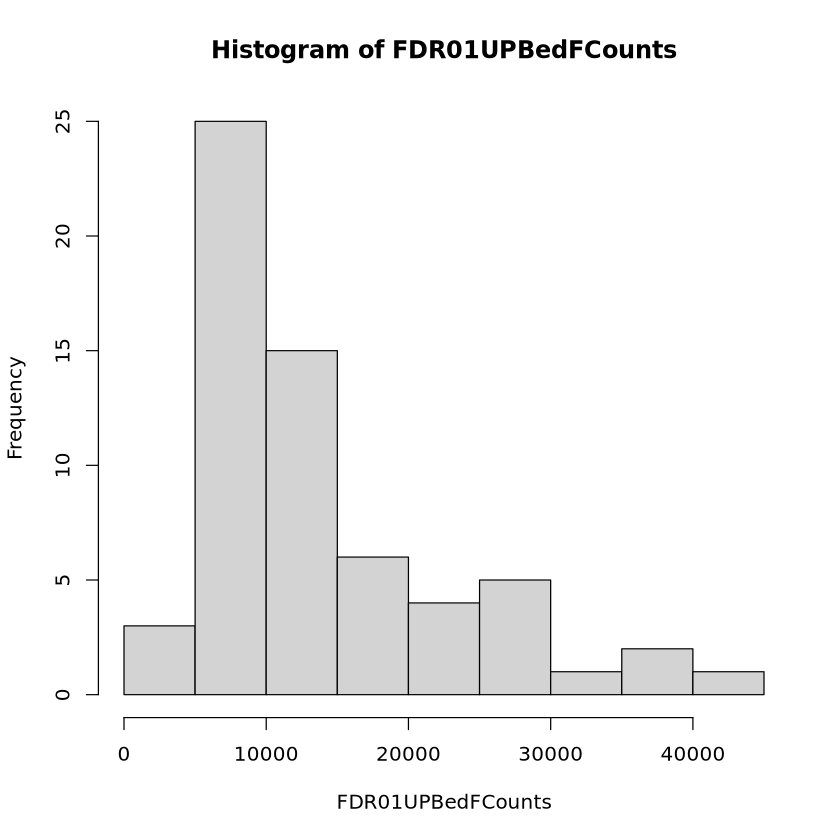

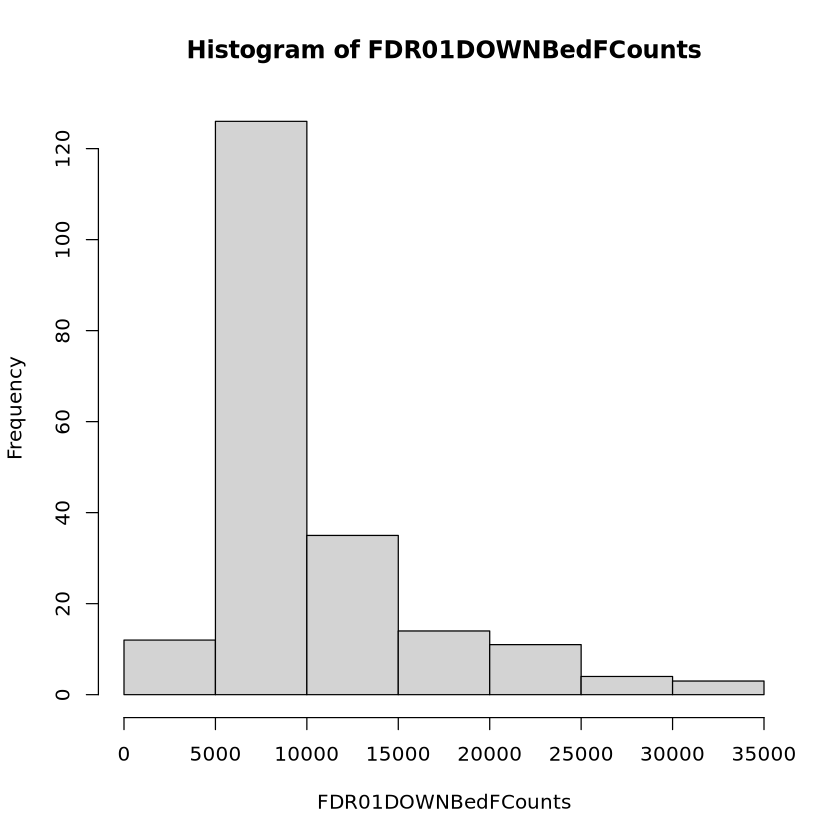

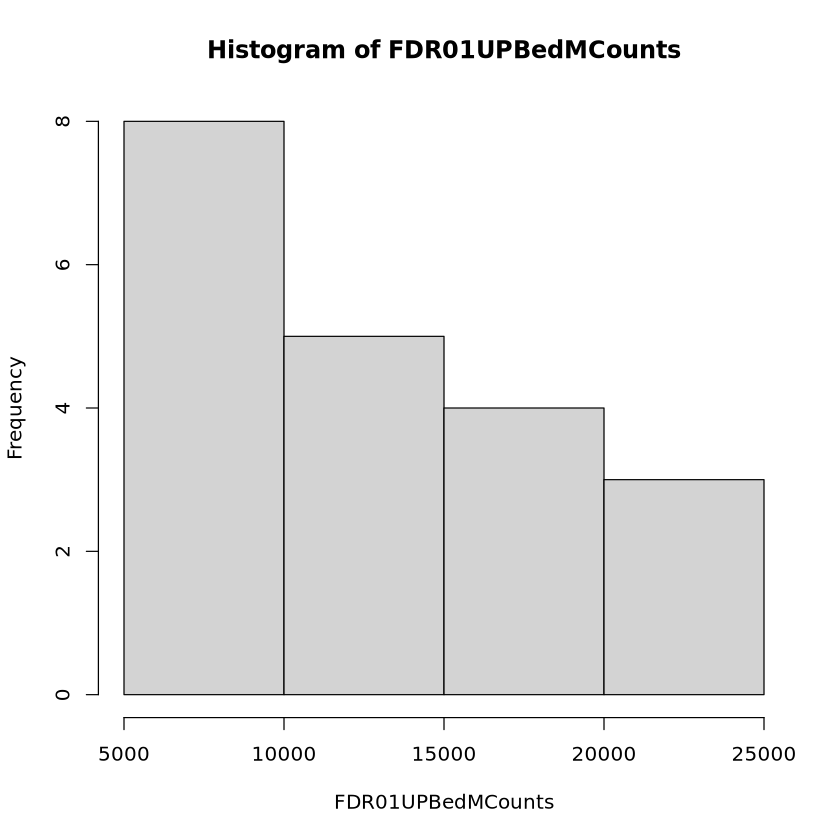

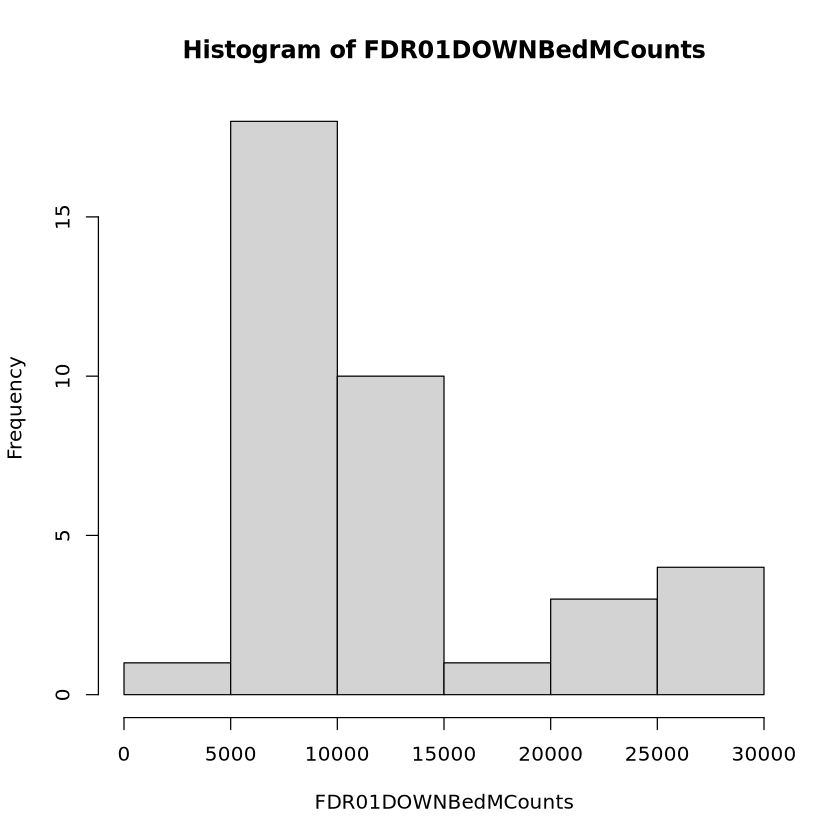

In [19]:
hist(FDR01UPBedFCounts)
hist(FDR01DOWNBedFCounts)
hist(FDR01UPBedMCounts)
hist(FDR01DOWNBedMCounts)
#hist(FDR01GLMCounts)
#hist(FDR01DESeqCounts)

In [20]:
# Arushi indicated this file will give us the nuclei that should be included in the analysis after qc
metadataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/cluster_info_qc.tsv", sep = "\t", header = TRUE)
batchdataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/batch-sample-info-full.tsv", sep = "\t", header = TRUE)
metadataFactors <- metadataFactors[(metadataFactors$modality == "atac") & (metadataFactors$demux_cat != "multiome"),]
metadataFactors <- merge(metadataFactors, batchdataFactors, by = "SNG.1ST")

femDs <- batchdataFactors[batchdataFactors$sex == "F",]$SNG.1ST
#memDs <- batchdataFactors[batchdataFactors$sex == "M",]$SNG.1ST
metadataFactorsClustF <- metadataFactors[(metadataFactors$coarse_cluster_name == cDex) & (metadataFactors$SNG.1ST %in% femDs),]
#metadataFactorsClustM <- metadataFactors[(metadataFactors$coarse_cluster_name == cDex) & (metadataFactors$SNG.1ST %in% memDs),]

In [21]:

#Get files downloaded locally and send Steve nuclei plots for normal behaving (big coef tiny p) and oddly behaving genes (small coef tiny p)BY TOMORROW
    #Age on x by TPM normalized expression on y, per nucleus level. Steve guesses strong p small effect have big outliers on nuclei level
sceFCounts <- data.frame(counts(sceF))

#head(metadataFactorsClustF)
metadataJustAge <- metadataFactorsClustF %>% select(index, barcode, age, SNG.1ST)
#head(colnames(sceFCounts))
#head(metadataJustAge)
# Barcodes from sceFCounts that don't match to one from the metadata get assigned to an NA SNG.1ST
metadataJustAge <- metadataJustAge[match(colnames(sceFCounts), metadataJustAge$index),]
metadataJustAgeS <- metadataJustAge %>% select(age, SNG.1ST) %>% unique() %>% arrange(age)
#head(metadataJustAge)
#all(colnames(sceFCounts) == colnames(sceMCounts))
#dim(sceFCounts)
sceFCounts <- rbind(sceFCounts, metadataJustAge$age)
sceFCounts <- rbind(sceFCounts, metadataJustAge$SNG.1ST)
sceFCounts <- data.frame(t(sceFCounts))
sceFCounts$X6 <- factor(sceFCounts$X6, levels=metadataJustAgeS$SNG.1ST)
sceFCounts$X5 <- as.numeric(sceFCounts$X5)
#colnames(sceFCounts)

In [22]:
head(sceFCounts)

,chr11.8707647.8707948,chr2.237886721.237887022,chr5.3351763.3352064,chr6.31822068.31822369,X5,X6
,<chr>,<chr>,<chr>,<chr>,<dbl>,<fct>
atac.499.NM.1.AAAGGGCAGGTAGGCT,2,0,0,3,53,12055
atac.499.NM.1.AAAGGGCCATCGGCTG,0,2,0,3,70,32084
atac.499.NM.1.AAAGGGCGTGATAGAT,0,0,0,3,62,32029
atac.499.NM.1.AAATGAGAGTACGACG,0,0,0,2,70,32084
atac.499.NM.1.AAATGAGCAGCAGGTA,3,0,0,2,62,32029
atac.499.NM.1.AAATGCCAGCAGGAGG,0,0,0,0,53,32074


In [19]:
median(sceMCounts$X5)
sceMCounts$AgeGroup <- (sceMCounts$X5 <= 59)
sum(sceMCounts$AgeGroup) / nrow(sceMCounts)

[1] 60

[1] 0.4804809

In [23]:
coords <- "chr11.8707647.8707948"
sceMCountsSumm <- sceFCounts %>% group_by(X6) %>% summarize(
    age = median(as.numeric(X5)),
    averageS = median(as.numeric(chr11.8707647.8707948)), 
    minS = min(as.numeric(chr11.8707647.8707948)), 
    maxS = max(as.numeric(chr11.8707647.8707948)))
sceMCountsSumm <- sceMCountsSumm[!(is.na(sceMCountsSumm$age)),]
#sceMCountsSumm
sceFCounts$AgeGroup <- "Error"
sceFCounts[sceFCounts$X5 <= 60,]$AgeGroup <- "Younger"
sceFCounts[sceFCounts$X5 > 60,]$AgeGroup <- "Older"
sceFCounts$AgeGroup <- factor(sceFCounts$AgeGroup, levels = c("Younger", "Older"))

#pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_log2TPM1_Samp.pdf"), width=10, height=8)
#mygg <- ggplot(data=sceMCountsSumm, aes(x=X5563, y=averageS, color = zeroP)) +
#  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
#  geom_point(alpha = 0.9) + theme_bw() +
#  xlab("Sample") + ylab("Median Gene log2(TPM+1) Post DecontX Counts")+ ggtitle(coords) +
#  theme(axis.text.x = element_text(size = 6, angle = 90, vjust = 0.5, hjust=1))
#mygg
#dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/PeakLook/{coords}_Male_{cDex}_Counts_DensityGroup.pdf"), width=10, height=8)
mygg <- ggplot(data=sceFCounts, aes(x=as.numeric(chr11.8707647.8707948), color=AgeGroup, fill=AgeGroup)) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_histogram(position="dodge", bins = 30) + theme_bw() +
  xlab("Counts") + ylab("Frequency")+ ggtitle(coords)
mygg
dev.off()

pdf 
  2

In [4]:
# Load in all formatted fiber types at once for plots that recquire all the different results

Type1Frame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_Type_1.tsv"), sep = "\t") 
Type1F <- Type1Frame %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_1") %>% mutate(direction = (estimate > 0))
Type1fraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_Type_1.tsv"), sep = "\t") 
Type1M <- Type1fraMe %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_1") %>% mutate(direction = (estimate > 0))
Type2aFrame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_Type_2a.tsv"), sep = "\t") 
Type2aF <- Type2aFrame %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_2a") %>% mutate(direction = (estimate > 0))
Type2afraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_Type_2a.tsv"), sep = "\t") 
Type2aM <- Type2afraMe %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_2a") %>% mutate(direction = (estimate > 0))
Type2xFrame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_Type_2x.tsv"), sep = "\t") 
Type2xF <- Type2xFrame %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_2x") %>% mutate(direction = (estimate > 0))
Type2xfraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_Type_2x.tsv"), sep = "\t") 
Type2xM <- Type2xfraMe %>% filter(p_FDR < 0.05) %>%
            select(index, estimate) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_2x") %>% mutate(direction = (estimate > 0))
UpsetFrame <- rbind(Type1F, Type1M, Type2aF, Type2aM, Type2xF, Type2xM) %>% 
                mutate(Type_1 = (nuclei == "Type_1")) %>% mutate(Type_2a = (nuclei == "Type_2a")) %>% mutate(Type_2x = (nuclei == "Type_2x")) %>% 
                mutate(Female = (sex == "F")) %>% mutate(Male = (sex == "M")) %>%
                mutate(UP = (direction)) %>% mutate(DOWN = (!direction)) %>% 
                filter(sex == "M") %>% #############################################################################################################
                select(index, Type_1, Type_2a, Type_2x, Female, Male, UP, DOWN) %>% group_by(index) %>% summarise(across(everything(), ~ any(.))) %>%
                mutate(
                    combination = pmap(
                      list(Type_1, Type_2a, Type_2x),
                      \(T1, T2a, T2x) {
                        c('Type 1', 'Type 2a', 'Type 2x')[c(T1, T2a, T2x)] 
                      }
                    )
                )

In [38]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FibersOnly_M_ATACUpset_FDR01.pdf"), width=12, height=8)
mygg <- ggplot(UpsetFrame, aes(x = combination)) +
  geom_bar() + theme_bw() + 
  scale_x_upset() +
  xlab("Fiber Type") + ylab("Age-Associated Peak Count")
mygg
dev.off()

pdf 
  2

In [3]:
totalFrame <- rbind(Type1F, Type1M, Type2aF, Type2aM, Type2xF, Type2xM)
totalUP <- nrow(totalFrame[(totalFrame$estimate > 0),])
totalDOWN <- nrow(totalFrame[(totalFrame$estimate < 0),])
barFrame <- data.frame(Pattern = c("Opening", "Closing"), Peaks = c(totalUP, totalDOWN))
barFrame
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/FibersOnly_ATACPattern_FDR005.pdf"), width=8, height=6)
mygg <- ggplot(barFrame, aes(x = Pattern, y = Peaks, fill = Pattern)) +
  geom_bar(stat = "identity") + theme(text=element_text(size=24)) + theme_bw() +
  scale_fill_manual(values = c("Closing" = "#4AE4CB", "Opening" = "#CC6677")) +
  xlab("Peak Behavior") + ylab("Age-Associated Peak Count")
mygg
dev.off()

Pattern,Peaks
<chr>,<int>
Opening,856
Closing,2007


pdf 
  2

In [6]:
print("Female Fiber Type Comparisons")
CompDF <- merge(Type1Frame,Type2aFrame, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type1vType2a_Fe_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y)))  +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#68D0C4")) +  
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type1Frame,Type2xFrame, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type1vType2x_Fe_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type2aFrame,Type2xFrame, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type2avType2x_Fe_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) + 
        scale_color_manual(values=c("#000000", "#68D0C4", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

[1] "Female Fiber Type Comparisons"


[1] 0.8830074

pdf 
  2

[1] 266

[1] 0.3239951

...

[1] 0.6590585

[1] 27

[1] 0.03851641

[1] 40

[1] 0.05706134

In [8]:
print("Male Fiber Type Comparisons")
CompDF <- merge(Type1fraMe,Type2afraMe, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type1vType2a_Ma_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#68D0C4")) +  
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type1fraMe,Type2xfraMe, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type1vType2x_Ma_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y)))  +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type2afraMe,Type2xfraMe, by = "index") %>% dplyr::select(index, p_GLMMNB.x, p_FDR.x, estimate.x, p_GLMMNB.y, p_FDR.y, estimate.y)
colnames(CompDF) <- c("Row.names", "p_GLMMNB.x", "p_FDR.x", "estimate.x", "p_GLMMNB.y", "p_FDR.y", "estimate.y")
CompDF$modp.MAST <- -log10(CompDF$p_GLMMNB.x)*sign(CompDF$estimate.x)
CompDF$modp.DESeq <- -log10(CompDF$p_GLMMNB.y)*sign(CompDF$estimate.y)
if (nrow(CompDF[(is.na(CompDF$p_FDR.x)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.x)),]$p_FDR.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$p_FDR.y)),]) > 0) {
    CompDF[(is.na(CompDF$p_FDR.y)),]$p_FDR.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p_FDR.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[CompDF$p_FDR.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$p_FDR.y < 0.05) & (CompDF$p_FDR.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/CompareGLMMNB_Type2avType2x_Ma_Nom_FDR005.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p_GLMMNB.x)*sign(estimate.x), y=-log10(p_GLMMNB.y)*sign(estimate.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) + 
        scale_color_manual(values=c("#000000", "#68D0C4", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

[1] "Male Fiber Type Comparisons"


[1] 1.524362

pdf 
  2

[1] 328

[1] 0.2869641

...

[1] 0.6507937

[1] 34

[1] 0.02346446

[1] 43

[1] 0.02967564